#### Multiple Linear regression

#### Algorithm :
1. Start the program.
2. Import required libraries such as pandas, numpy, matplotlib, seaborn, and sklearn.
3. Load the dataset from the CSV file.
4. Display the dataset and check basic information (head, shape, correlation).
5. Select the independent variable (X) and dependent variable (y).
6. Split the dataset into training data and testing data.
7. Apply feature scaling (standardization) to the independent variable.
8. Create the Linear Regression model.
9. Train (fit) the model using training data.
10. Obtain slope (coefficient) and intercept values.
11. Predict the output for test data.
12. Calculate performance metrics:
      - Mean Absolute Error (MAE)
      - Mean Squared Error (MSE)
      - Root Mean Squared Error (RMSE)

13. Compute R² score to check model accuracy.
14. Plot the regression line with actual data points.
15. Use the model to predict new values.
16. Stop the program.

In [3]:
# Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [7]:
# Load the dataset
df = pd.read_csv('economic_index.csv')

In [8]:
# Display dataset
df.head()

,Unnamed: 0,year,month,interest_rate,unemployment_rate,index_price
0,0,2017,12,2.75,5.3,1464
1,1,2017,11,2.50,5.3,1394
2,2,2017,10,2.50,5.3,1357
3,3,2017,9,2.50,5.3,1293
4,4,2017,8,2.50,5.4,1256


In [11]:
# Drop useless Column
df.drop(columns = ['Unnamed: 0','year','month'],axis=1,inplace=True)

In [17]:
df.columns

Index(['interest_rate', 'unemployment_rate', 'index_price'], dtype='object')

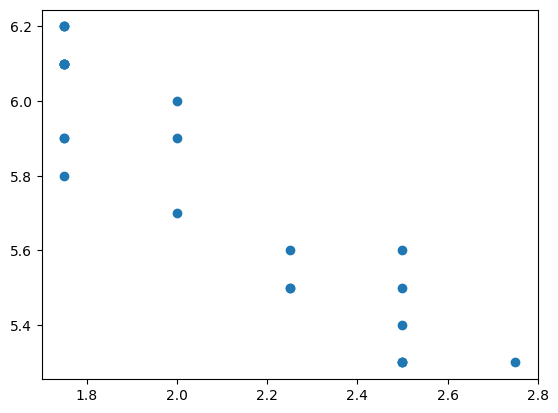

In [21]:
# Scatter Plot
plt.scatter(df['interest_rate'],df['unemployment_rate'])
plt.show()

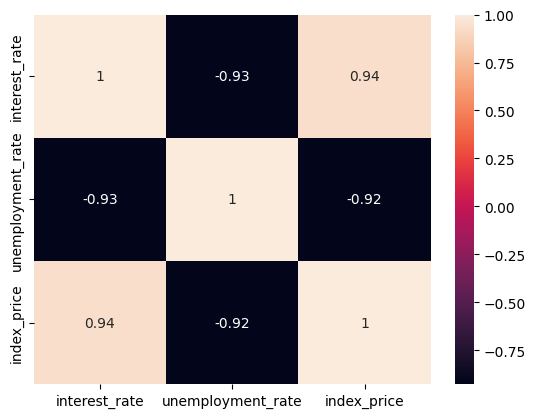

In [25]:
# Check correlation
sns.heatmap(df.corr(),annot=True)
plt.show()

In [28]:
# Intitalize input feature in X and target in y
x = df[['interest_rate', 'unemployment_rate']]
y = df['index_price']

In [29]:
# Train test split 
from sklearn.model_selection import train_test_split

In [30]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.25,random_state=42)

In [38]:
# Standrization
from sklearn.preprocessing import StandardScaler
scaller = StandardScaler()
x_train = scaller.fit_transform(x_train)
x_test = scaller.fit_transform(x_test)

In [ ]:
# Apply Linear Regression
from sklearn.linear_model import LinearRegression

In [42]:
model = LinearRegression()
model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [72]:
predict = model.predict(x)
predict

c:\Users\shali\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


array([680.03156939, 657.96338062, 657.96338062, 657.96338062,
       646.33766456, 623.08623242, 634.71194849, 612.64375972,
       612.64375972, 601.01804366, 567.32413882, 544.07270669,
       532.44699062, 522.00451792, 533.63023399, 498.75308579,
       487.12736973, 498.75308579, 498.75308579, 498.75308579,
       522.00451792, 487.12736973, 487.12736973, 498.75308579])

In [69]:
df.columns

Index(['interest_rate', 'unemployment_rate', 'index_price'], dtype='object')

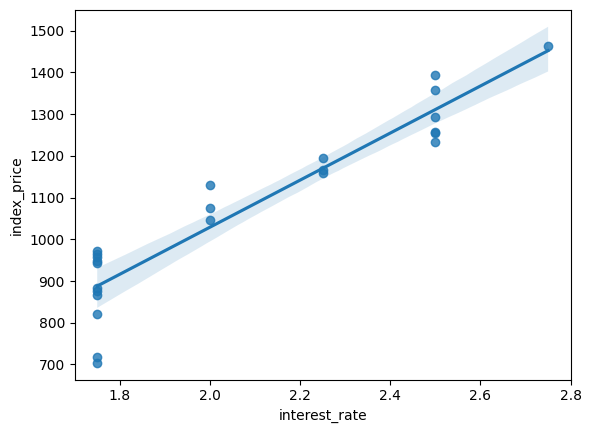

In [ ]:
# Plot best fit line : in multiple regression i can't plot directly
sns.regplot(x = 'interest_rate',y = 'index_price',data=df)
plt.show()

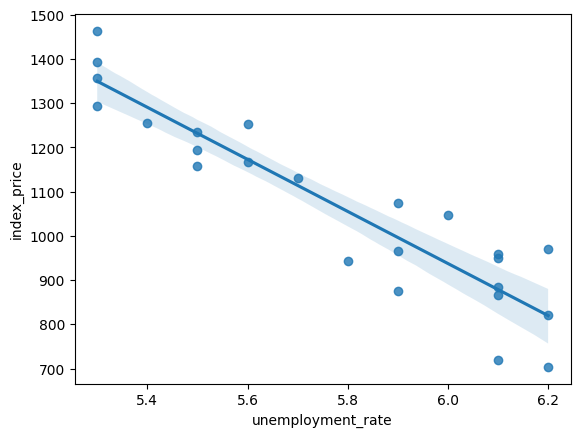

In [94]:
sns.regplot(x='unemployment_rate',y = 'index_price',data=df)
plt.show()

In [97]:
# Slope and intercept
print(f'Slpoe or coeffcient : {model.coef_}')
print(f'Intercept : {model.intercept_}')

Slpoe or coeffcient : [  88.27275507 -116.25716066]
Intercept : 1053.4444444444443


In [105]:
test_predict = model.predict(x_test)
test_predict

array([1180.7466813 ,  802.74279699, 1379.83457045,  838.52599602,
        973.85313963, 1144.96348227])

In [104]:
## Performance Matrix
### Performance Matrix
from sklearn.metrics import mean_absolute_error,mean_squared_error
mse = mean_squared_error(y_test,test_predict)
rmse = np.sqrt(mse)
rmse

np.float64(90.04758423359621)

In [107]:
# (Accuracy of Model)
from sklearn.metrics import r2_score
r2_score(y_test,test_predict)

0.7591371539010257

In [121]:
# Predict New Value
model.predict(scaller.fit_transform([[2.5,6]]))

array([1053.44444444])